# Multigrain Tutorial

This tutorial generates a tetrahedral four-grain geometry with an explicit grain-boundary phase, explores the mesh interactively with PyVista, and converts it into a region-aware Ubermag system for TOMMOS.

In [19]:
import mammos_analysis
import mammos_entity as me
import matplotlib.pyplot as plt
import micromagneticdata as mdata
import micromagneticmodel as mm
import numpy as np
import pyvista as pv

import tommos_adapter as ta

pv.set_jupyter_backend("server")

## Generate a multigrain mesh

TOMMOS delegates the polycrystal construction to Neper and then creates a tetrahedral volume mesh. The command below generates a $40\,\mathrm{nm}$ cube containing four grains. `--h` controls the target grain-mesh spacing, while `--gb-thickness` and `--gb-h` control the explicit grain-boundary phase. `--id 7` selects a fixed Neper seed for the microstructure.

Two files are written: `multigrain.npz` contains the TOMMOS solver mesh and `multigrain.vtu` contains the equivalent mesh for visualization and further processing with PyVista.

In [2]:
!tommos mesh \
    --geom poly_gb \
    --extent 40,40,40 \
    --h 3 \
    --n 4 \
    --id 7 \
    --gb-thickness 2 \
    --gb-h 1.5 \
    --out-name multigrain


========================    N   e   p   e   r    =======================
Info   : A software package for polycrystal generation and meshing.
Info   : Version 5.0.0
Info   : Built with: gsl|muparser|opengjk|openmp|nlopt|libscotch (full)
Info   : Running on 10 threads.
Info   : <https://neper.info>
Info   : Copyright (C) 2003-2026, and GNU GPL'd, by Romain Quey, CNRS.
Info   : No initialization file found (`/Users/michael/.neperrc').
Info   : ---------------------------------------------------------------
Info   : MODULE  -T loaded with arguments:
Info   : [ini file] (none)
Info   : [com line] -n 4 -id 7 -morpho gg -morphooptistop val=0.1 -domain
         cube(40.0,40.0,40.0):translate(0,0,0) -format tess,obj -reg 1
Info   : ---------------------------------------------------------------
Info   : Reading input data...
Info   : Creating domain...
Info   : Creating tessellation...
Info   :   - Setting seeds... 255075100%
Info   :   - Running tessellation...
Info   :     > Initial solution

## Inspect the generated mesh using PyVista

### Import the VTU file and check its regions

The VTU file stores the tetrahedral mesh and one material ID for each cell. The following summary reports the number of points and cells, the spatial extents, and the number of tetrahedra belonging to every material. This is a useful first consistency check before assigning physical parameters.

In [3]:
mesh = pv.read("multigrain.vtu")
# TOMMOS stores one material identifier per tetrahedron.
material_ids = np.asarray(mesh.cell_data["mat_id"])

mesh

UnstructuredGrid (0x326adbbe0)
  N Cells:    415443
  N Points:   83085
  X Bounds:   -2.000e+01, 2.000e+01
  Y Bounds:   -2.000e+01, 2.000e+01
  Z Bounds:   -2.000e+01, 2.000e+01
  N Arrays:   1

In [4]:
print("Material IDs:", np.unique(material_ids))

ids, counts = np.unique(material_ids, return_counts=True)
for material_id, count in zip(ids, counts, strict=True):
    print(f"Material {material_id}: {count} tetrahedra")

Material IDs: [1 2 3 4 5]
Material 1: 16359 tetrahedra
Material 2: 33083 tetrahedra
Material 3: 67365 tetrahedra
Material 4: 16229 tetrahedra
Material 5: 282407 tetrahedra


### Inspect the grains and grain boundary in three dimensions

The next view separates the magnetic grains from the grain-boundary phase. The grains are colored by material ID, while the grain boundary is rendered transparently so that the internal microstructure remains visible.

In [5]:
# The poly_gb mesher assigns the final material ID to the grain boundary.
mesh.threshold(4, method="lower").plot()

Widget(value='<iframe src="http://localhost:64496/index.html?ui=P_0x326397590_0&reconnect=auto" class="pyvista…

### Explore two-dimensional slices of the tetrahedral mesh

A full tetrahedral mesh can be difficult to inspect from the outside. The following plot therefore shows an $xy$ section through the mesh. Move the slider to select the section's $z$ coordinate; colors denote the material IDs and the black box marks the full mesh extent.

In [6]:
# Server-side rendering keeps the interactive clipping plane without
# serializing the VTK arrays for client-side rendering.
pl = pv.Plotter()
pl.add_mesh(mesh.outline(), color="black", line_width=2)
pl.add_mesh_clip_plane(mesh, normal="z", invert=True, scalars="mat_id")
pl.show()

Widget(value='<iframe src="http://localhost:64496/index.html?ui=P_0x32cbf7dd0_1&reconnect=auto" class="pyvista…

## Setting the initial magnetization

The generated coordinates are expressed in nanometres, whereas Ubermag models use SI units. The adapter also expects the cell-wise material identifiers under `region_id`, optional human-readable region metadata in `field_data`, and a unit magnetization vector `m` at every mesh point.

In [7]:
mesh_si = mesh.copy(deep=True)
mesh_si.points *= ta.scripts.DEFAULT_MESH_UNIT
mesh_si.cell_data["region_id"] = material_ids

ids = np.unique(material_ids)
grain_boundary_id = ids.max()
names = [f"grain_{i}" if i != grain_boundary_id else "grain_boundary" for i in ids]

# Region names allow energy parameters to be assigned with dictionaries.
mesh_si.field_data["region_ids"] = ids
mesh_si.field_data["region_names"] = names

# Start from a uniform, normalized magnetization along +z.
mesh_si.point_data["m"] = np.tile((0, 0, 1), (mesh_si.n_points, 1))

## Define the micromagnetic system using Ubermag

The material parameters below are illustrative. The four grains are magnetic and share the same material parameters and easy-axis direction. The grain-boundary phase is non-magnetic. Region dictionaries connect the named PyVista regions to the corresponding Ubermag energy parameters.

In [8]:
Ms = {"default": 1e6, "grain_boundary": 0.0}
A = {"default": 1e-11, "grain_boundary": 0.0}
K = {"default": 4e5, "grain_boundary": 0.0}
u = {
    "default": (0, 0, 1),
    "grain_2": (0, 1, 0),
    "grain_3": (1, 0, 0),
}

mesh_si.cell_data["Ms"] = np.full(mesh_si.n_cells, Ms["default"])
mesh_si.cell_data["Ms"][material_ids == grain_boundary_id] = Ms["grain_boundary"]

system = mm.System(name="multigrain")
system.m = mesh_si
system.energy = mm.Exchange(A=A) + mm.UniaxialAnisotropy(K=K, u=u) + mm.Demag()
system

System(name='multigrain')

## Prepare a hysteresis calculation

The following field sweep starts at $+2\,\mathrm{T}$ along the easy axis and ends at $-2\,\mathrm{T}$. Thirty field points provide a compact technical demonstration; they are not intended to produce a well-resolved physical hysteresis curve.

In [9]:
mu0 = mm.consts.mu0
hd = ta.HysteresisDriver()
hd.drive(system, h_direction=(0, 0, 1), h_start=2.0 / mu0, h_final=-2.0 / mu0, n=30)

Running Tommos (TommosRunner)[2026-11-13T11:16:36]... (355.7 s)


In [10]:
system.m

UnstructuredGrid (0x32cc1e380)
  N Cells:    415443
  N Points:   83085
  X Bounds:   -2.000e-08, 2.000e-08
  Y Bounds:   -2.000e-08, 2.000e-08
  Z Bounds:   -2.000e-08, 2.000e-08
  N Arrays:   6

### Plot the final magnetization vector field

After the drive, the adapter maps the final magnetization back onto the original system mesh, so `system.m` does not contain the TOMMOS Airbox. For this plot, cells with $M_\mathrm{s}=0$ are removed to hide the non-magnetic grain-boundary phase. PyVista's `glyph` filter converts the nodal `m` vectors into arrows. The arrow length is derived from the SI-scaled domain size, `tolerance` reduces their density, and the arrow color represents the $z$ component $m_z$.

In [11]:
# NBVAL_SKIP
magnetic_state = system.m.extract_cells(np.asarray(system.m.cell_data["Ms"]) > 0)
magnetic_state.point_data["m_z"] = np.asarray(magnetic_state.point_data["m"])[:, 2]
domain_lengths = np.array(
    [
        magnetic_state.bounds[1] - magnetic_state.bounds[0],
        magnetic_state.bounds[3] - magnetic_state.bounds[2],
        magnetic_state.bounds[5] - magnetic_state.bounds[4],
    ]
)
glyph_length = 0.05 * domain_lengths.max()

magnetization_glyphs = magnetic_state.glyph(
    orient="m",
    scale=False,
    factor=glyph_length,
    tolerance=0.04,
)

vector_plotter = pv.Plotter()
vector_plotter.add_mesh(
    magnetic_state.extract_surface(algorithm="dataset_surface"),
    scalars="region_id",
    categories=True,
    opacity=0.15,
    show_scalar_bar=False,
)
vector_plotter.add_mesh(
    magnetization_glyphs,
    scalars="m_z",
    cmap="coolwarm",
    clim=(-1, 1),
    scalar_bar_args={"title": "m_z"},
)
vector_plotter.add_axes()
vector_plotter.show()

Widget(value='<iframe src="http://localhost:64496/index.html?ui=P_0x331814dd0_2&reconnect=auto" class="pyvista…

### Plot the average magnetization of each grain

Instead of displaying the complete nodal vector field, the next view shows one volume-weighted magnetization vector per grain. Each arrow is centered on the volume-weighted grain center, its direction is the mean magnetization direction, and its length represents the magnitude of the mean. `micromagneticdata` provides access to all TOMMOS snapshots while restoring the original system grid without the Airbox. Use the slider to select a snapshot; states are loaded on demand and only their four averaged vectors are cached.

In [12]:
# NBVAL_SKIP
drive = mdata.Data(name=system.name)[-1]
slider_fields = drive.table.data[drive.x].to_numpy()
if drive.n < 2:
    raise RuntimeError("At least two TOMMOS snapshots are required for the slider.")

magnetic_region_ids = np.unique(np.asarray(system.m.cell_data["region_id"])[np.asarray(system.m.cell_data["Ms"]) > 0])


def grain_average_data(state):
    """Return one volume-weighted magnetization vector per grain."""
    state_region_ids = np.asarray(state.cell_data["region_id"])
    centers = []
    mean_magnetizations = []

    for region_id in magnetic_region_ids:
        grain = state.extract_cells(state_region_ids == region_id)
        grain_cells = grain.point_data_to_cell_data().compute_cell_sizes(length=False, area=False, volume=True)
        volumes = np.asarray(grain_cells.cell_data["Volume"])
        centers.append(np.average(grain.cell_centers().points, axis=0, weights=volumes))
        mean_magnetizations.append(
            np.average(
                np.asarray(grain_cells.cell_data["m"]),
                axis=0,
                weights=volumes,
            )
        )

    mean_magnetizations = np.asarray(mean_magnetizations)
    averages = pv.PolyData(np.asarray(centers))
    averages.point_data["m_mean"] = mean_magnetizations
    averages.point_data["m_mean_norm"] = np.linalg.norm(mean_magnetizations, axis=1)
    averages.point_data["m_mean_z"] = mean_magnetizations[:, 2]
    averages.point_data["region_id"] = magnetic_region_ids
    return averages


centered_arrow = pv.Arrow(start=(-0.5, 0, 0), direction=(1, 0, 0))


def average_glyphs(averages):
    """Create one arrow for every grain average."""
    return averages.glyph(
        orient="m_mean",
        scale="m_mean_norm",
        factor=arrow_length,
        geom=centered_arrow,
    )


arrow_length = 0.2 * max(domain_lengths)
initial_snapshot = drive.n - 1
initial_state = drive[initial_snapshot]
grain_average_cache = {initial_snapshot: grain_average_data(initial_state)}
mean_glyphs = average_glyphs(grain_average_cache[initial_snapshot])

grain_average_plotter = pv.Plotter()
grain_average_plotter.add_mesh(
    magnetic_state.extract_surface(algorithm="dataset_surface"),
    scalars="region_id",
    categories=True,
    cmap="tab10",
    opacity=0.2,
    show_scalar_bar=False,
)
grain_average_plotter.add_mesh(
    mean_glyphs,
    scalars="m_mean_z",
    cmap="coolwarm",
    clim=(-1, 1),
    scalar_bar_args={"title": "mean m_z"},
)
field_label = grain_average_plotter.add_text(
    f"B = {slider_fields[initial_snapshot]:+.4f} T",
    position="upper_left",
)


def update_grain_averages(snapshot_index):
    """Update the arrows when the snapshot slider is released."""
    snapshot_index = int(np.clip(round(snapshot_index), 0, drive.n - 1))
    if snapshot_index not in grain_average_cache:
        state = drive[snapshot_index]
        grain_average_cache[snapshot_index] = grain_average_data(state)

    mean_glyphs.copy_from(average_glyphs(grain_average_cache[snapshot_index]), deep=True)
    field_label.set_text(
        "upper_left",
        f"B = {slider_fields[snapshot_index]:+.4f} T",
    )
    grain_average_plotter.render()


grain_average_plotter.add_slider_widget(
    update_grain_averages,
    rng=(0, drive.n - 1),
    value=initial_snapshot,
    title="snapshot",
    fmt="%.0f",
    interaction_event="end",
)
grain_average_plotter.add_axes()
grain_average_plotter.show(jupyter_backend="server")

Widget(value='<iframe src="http://localhost:64496/index.html?ui=P_0x33cd21a50_3&reconnect=auto" class="pyvista…

### Read the scalar hysteresis data

The adapter reads the TOMMOS field sweep and volume-averaged quantities into `system.table`. The original MaMMoS columns `B_ext_T` and `J_par_T` are exposed as `B_hysteresis` and `J_par`, including their units and metadata.

In [13]:
system.table.data.head()

,config,B_hysteresis,J_par,E,gnorm
0,0.0,2.000000,1.253635,-1.884545e+06,104.179957
1,1.0,1.862069,1.253125,-1.746971e+06,105.303269
2,2.0,1.724138,1.252454,-1.609461e+06,97.318678
3,3.0,1.586207,1.251555,-1.472037e+06,99.905725
4,4.0,1.448276,1.250287,-1.334730e+06,111.344655


### Plot the hysteresis branch

`B_hysteresis` and `J_par` are signed scalar projections along the direction supplied as `h_direction`. Here this direction is $+\mathbf{e}_z$, so both columns already describe the corresponding laboratory $z$ components and require no additional sign conversion.

The current calculation contains a single sweep from the initial to the final field and therefore represents one hysteresis branch rather than a closed loop. The chosen field discretization is intended as a technical test; a physically resolved curve requires more field points.

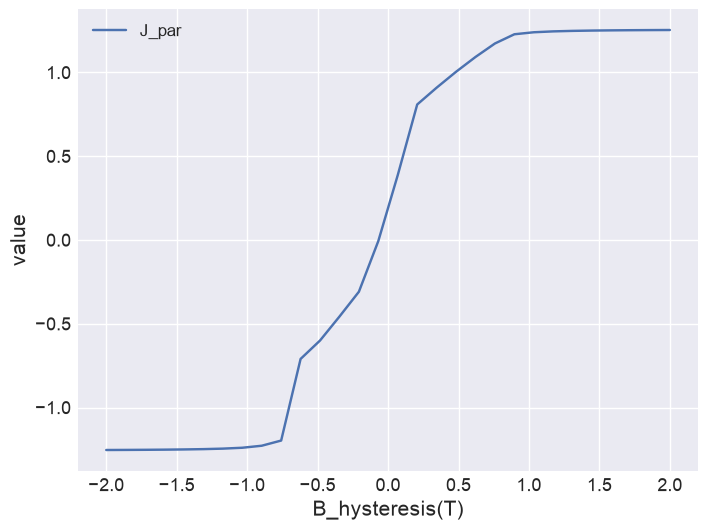

In [14]:
# NBVAL_SKIP
system.table.mpl(y=["J_par"])

## Analyse the hysteresis branch with MaMMoS Analysis

`mammos-analysis` extracts the coercive field $H_\mathrm{c}$, remanent magnetization $M_\mathrm{r}$, and maximum energy product $(BH)_\mathrm{max}$ from the descending hysteresis branch. TOMMOS reports the applied field as $\mu_0 H_\mathrm{ext}$ and the magnetic polarization as $J=\mu_0 M$, both in tesla, so the table columns are converted to $H$ and $M$ in $\mathrm{A\,m^{-1}}$ before analysis.

For $(BH)_\mathrm{max}$, MaMMoS Analysis applies a scalar demagnetizing-factor model. The value $N=1/3$ used below is the magnetometric approximation for the cubic specimen; it is a macroscopic average and not a local identity for the inhomogeneous magnetostatic field. With only 30 field points, all extracted values remain coarse technical estimates.

In [15]:
H_external = me.Entity(
    "ExternalMagneticField",
    system.table.data["B_hysteresis"].to_numpy() / mm.consts.mu0,
    unit="A / m",
)
M_parallel = me.Entity(
    "Magnetization",
    system.table.data["J_par"].to_numpy() / mm.consts.mu0,
    unit="A / m",
)

demagnetization_coefficient = 1 / 3
extrinsic_properties = mammos_analysis.hysteresis.extrinsic_properties(
    H=H_external,
    M=M_parallel,
    demagnetization_coefficient=demagnetization_coefficient,
)
extrinsic_properties

/Users/michael/Desktop/current_projects/ubermag_dev/tommos-adapter/.pixi/envs/default/lib/python3.11/site-packages/mammos_analysis/hysteresis.py:382: UserWarning: Only 2 (H_internal, M_internal) values in second quadrant - estimate of BHmax may be inaccurate.
  warnings.warn(


ExtrinsicProperties(Hc=Entity(ontology_label='CoercivityHcExternal', value=np.float64(53233.315863157775), unit='A / m'), Mr=Entity(ontology_label='Remanence', value=np.float64(151933.65948306175), unit='A / m'), BHmax=Entity(ontology_label='MaximumEnergyProduct', value=np.float64(37270.61118099623), unit='N / m2'))

In [16]:
print(f"Coercive field Hc: {extrinsic_properties.Hc.q}")
print(f"Remanent magnetization Mr: {extrinsic_properties.Mr.q}")
print(f"Maximum energy product BHmax: {extrinsic_properties.BHmax.q}")

Coercive field Hc: 53233.315863157775 A / m
Remanent magnetization Mr: 151933.65948306175 A / m
Maximum energy product BHmax: 37270.61118099623 N / m2


The following plot marks $J_\mathrm{r}=\mu_0M_\mathrm{r}$ and the coercive point $-\mu_0H_\mathrm{c}$ on the TOMMOS branch.

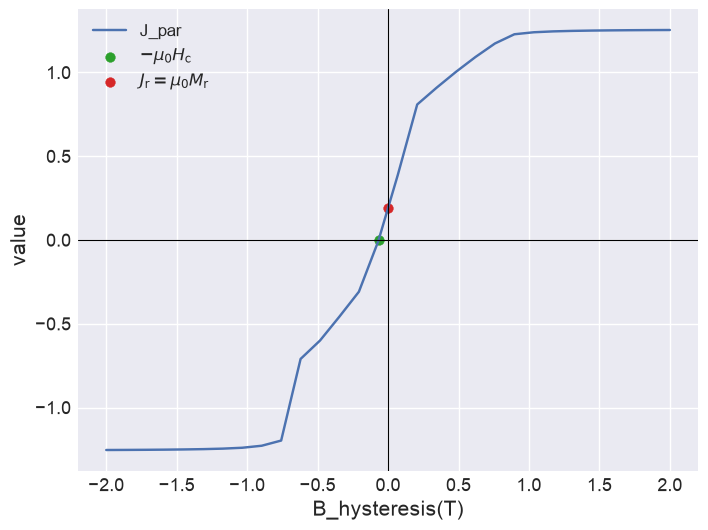

In [20]:
# NBVAL_SKIP
_, analysis_plot = plt.subplots()
system.table.mpl(y=["J_par"], ax=analysis_plot)
analysis_plot.scatter(
    -mm.consts.mu0 * extrinsic_properties.Hc.value,
    0,
    color="tab:green",
    label=r"$-\mu_0 H_\mathrm{c}$",
)
analysis_plot.scatter(
    0,
    mm.consts.mu0 * extrinsic_properties.Mr.value,
    color="tab:red",
    label=r"$J_\mathrm{r}=\mu_0 M_\mathrm{r}$",
)
analysis_plot.axhline(0, color="black", linewidth=0.8)
analysis_plot.axvline(0, color="black", linewidth=0.8)
analysis_plot.legend()